# One sample, one lane: `.at`, `hawk.scatter` and `sample_index`

Read your neighbour, total a block, and find out which lane you are: per-sample control, written as an ordinary kernel body.

**Time:** ~8 min · **Runs on:** CPU · **You need:** hawk, NumPy and matplotlib; read first: [Lookups, scatters and sums](06_lookups_scatters_and_sums)

A hawk kernel body describes ONE sample, and every sample runs it. Two names let that one sample reach beyond itself:

| Name | What it gives you |
|---|---|
| `hawk.math.sample_index()` | this sample's own position in the batch, as an integer value |
| `x.at(j)`, `hawk.scatter(acc)[key]` | the input `x` as sample `j` holds it; an add into the bin `key` names |

Together they cover what a plain per-sample body cannot say: "my left neighbour", "which block am I in". Here they smooth a signal and total it in blocks of four, and the result is checked against NumPy.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "hawk, matplotlib not found. Install with `pip install matplotlib raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import plot_style, show
plot_style()


## Read your neighbours

Smoothing replaces each value by a weighted mix of itself and its two neighbours. Sample `i` needs sample `i - 1` and `i + 1`, so it asks for them by index: `x.at(j)` is `x` as sample `j` holds it. The first and last samples have only one neighbour, so they read themselves instead:

In [3]:
import numpy as np

import hawk
from hawk import Mutable, Scalar
from hawk.math import n_samples, sample_index, select


@hawk.kernel
def smooth(x: Scalar, y: Mutable[Scalar]):
    i = sample_index()
    left = x.at(select(i > 0, i - 1, i))
    right = x.at(select(i < n_samples() - 1, i + 1, i))
    y = 0.25 * left + 0.5 * x + 0.25 * right


smooth

<Kernel smooth slots=3>

Build it and run it on a noisy sine, then compare with the same stencil written in NumPy:

In [4]:
import pathlib, tempfile

import hawk.artifact

work_dir = pathlib.Path(tempfile.mkdtemp())
n = 48
rng = np.random.default_rng(0)
x = np.sin(np.linspace(0.0, 2.0 * np.pi, n)) + 0.3 * rng.normal(size=n)
y = np.zeros(n)
hawk.artifact.build(smooth, work_dir, targets=("host",))
hawk.run(hawk.load(work_dir, "smooth"), x=x, y=y)

padded = np.r_[x[0], x, x[-1]]
expect = 0.25 * padded[:-2] + 0.5 * x + 0.25 * padded[2:]
print("matches the NumPy stencil:", np.allclose(y, expect))

matches the NumPy stencil: True



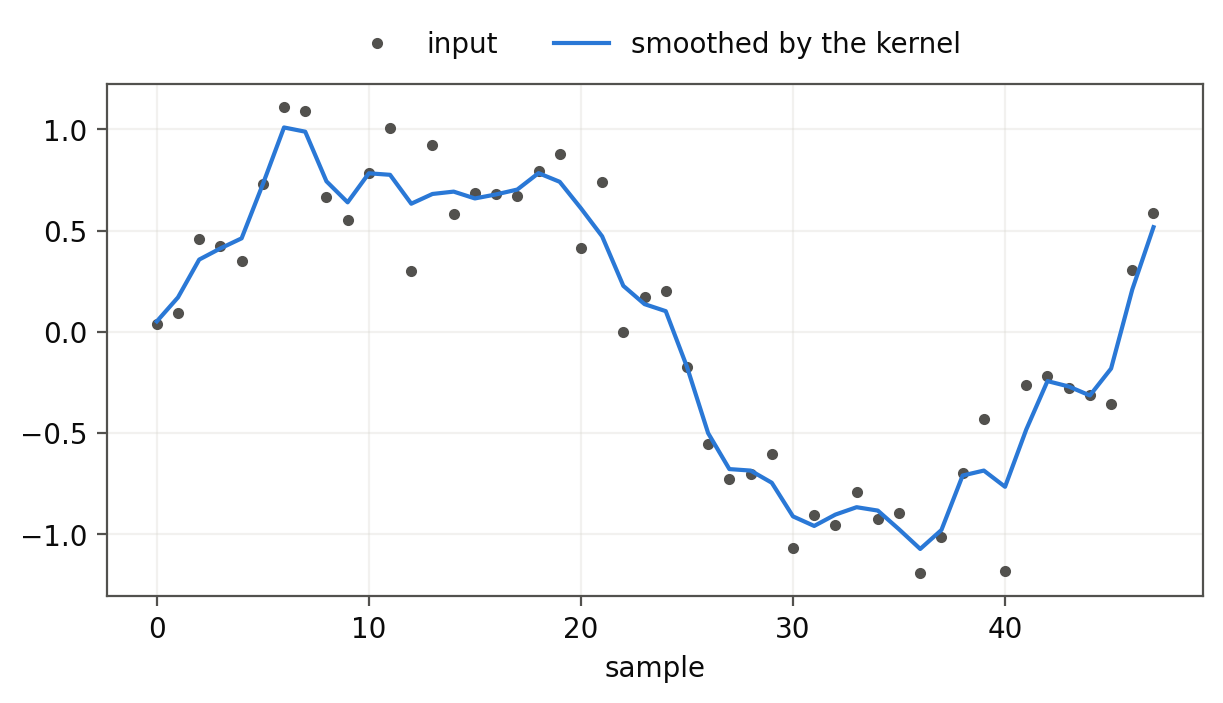
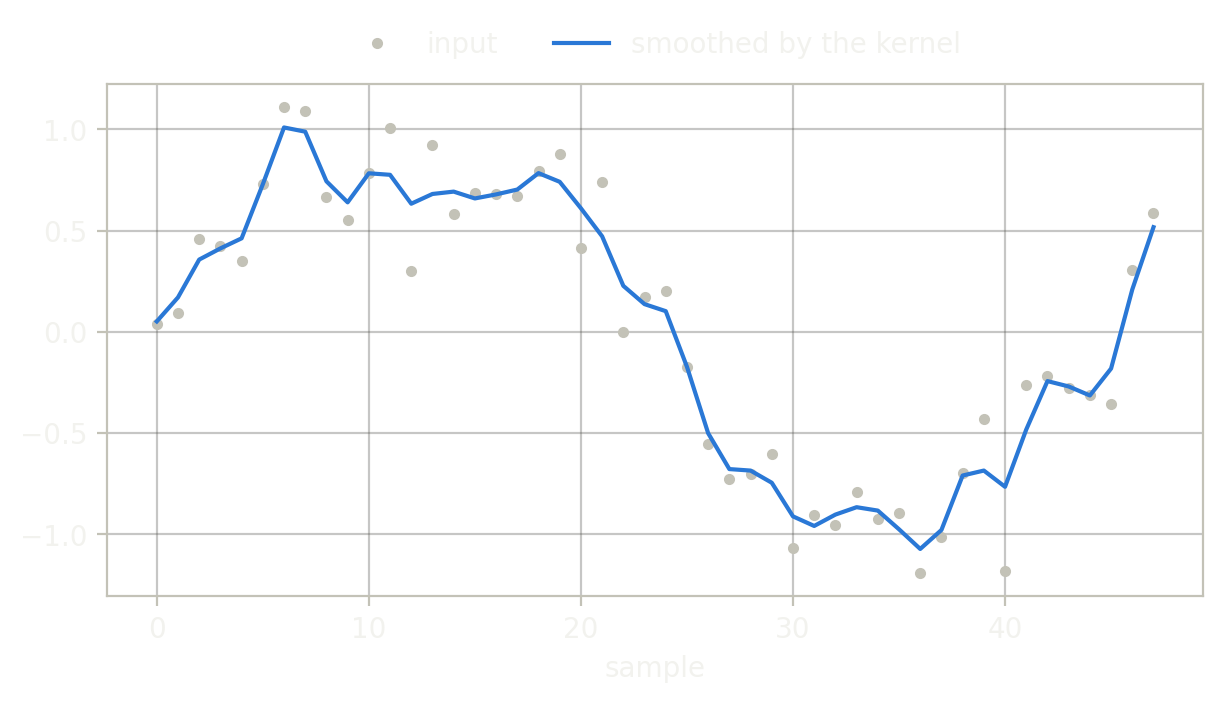

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.4), constrained_layout=True)
ax.plot(x, ".", color="#8a8a8a", label="input")
ax.plot(y, color="#2a78d6", label="smoothed by the kernel")
ax.set_xlabel("sample"); ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.grid(alpha=0.3)
show()

Nothing in the body loops over samples. `sample_index()` is a value like any other, so `i - 1` and the `select` are ordinary per-sample arithmetic; only the read `.at(...)` crosses to another sample.

## Total by block

`hawk.scatter(...)[key] += value` goes the other way: each sample adds its value into the bin `key` names. Using the sample's own position as the key, with `hawk.math.split_index(4)` returning its block (`i // 4`) and its place in the block (`i % 4`), totals every four consecutive samples:

In [6]:
from hawk.math import split_index


@hawk.kernel
def block_sums(x: Scalar, totals: Mutable[Scalar]):
    block, _place = split_index(4)
    hawk.scatter(totals)[block] += x


block_sums

<Kernel block_sums slots=3>

In [7]:
totals = np.zeros(n // 4)
hawk.artifact.build(block_sums, work_dir, targets=("host",))
hawk.run(hawk.load(work_dir, "block_sums"), x=x, totals=totals)
print("matches a reshape and sum:", np.allclose(totals, x.reshape(-1, 4).sum(axis=1)))

matches a reshape and sum: True


## What it costs

- **A neighbour read is an input read.** `x.at(j)` reads the input plane `x` at sample `j`. Only a plane that existed before the launch can be read at another sample, so a value computed in the body is recomputed from the inputs it needs.
- **A by-key `+=` is an atomic add.** Samples that share a key add in no fixed order, so a floating-point total can differ in its last digits from run to run. A sum to a cell with `hawk.run` is the way to a fixed order ([Across lanes](../across_lanes) lists the policies).
- **You cannot read what this launch is writing.** Another sample's `Mutable` output is not ready yet. Reading a reduced total in the body splits the kernel into stages, one launch each.
- **Indexing is by position.** `sample_index()` is the sample's place in the whole batch, so a kernel that uses it means the same thing however the batch is split across launches.

## When not to use it

If every sample only needs its own inputs, write the plain body: it is the fastest form and needs neither name. If the neighbours are the whole job on a regular grid, a NumPy slice or a convolution already says it in one line. Reach for `.at`, `hawk.scatter` and `sample_index` when the neighbour read sits inside a body that also does per-sample work (a branch, a stop, a lookup) that you want compiled as one kernel.

## What just happened

- `sample_index()` is the sample's own position, usable in arithmetic and as a key.
- `x.at(j)` reads sample `j`'s `x`; `hawk.scatter(acc)[key] += v` adds into shared bins; `split_index(m)` turns a position into a block and a place.
- Both read other samples without a Python loop, and each has a cost you can name.

## Try this

Change the stencil to reach two samples to the left and right (a five-point smooth) and check it against `np.convolve`.

## Next

[Describe your system once](../vocabulary/01_a_family_of_kernels) — declare a reusable kernel *shape* once, so a whole family of models shares one vocabulary.
*Deeper:* [Across lanes](../across_lanes) (masks, named axes, vector cells, reduction policies).